# H₂・CO・H–O 電荷交換の設定比較と描画

分子化学と H–O 電荷交換を切り替えたときの CPU 時間と、エネルギー更新後の温度・化学組成の差を表示します。入力は [計算ノートブック](../test/RunMolecularSettingsBenchmark.ipynb) または `make -C test molecular-settings-benchmark` で生成した CSV です。計算条件は [README](../README.md) にあります。

In [1]:
%matplotlib inline

import sys

from pathlib import Path

cwd = Path.cwd()
repo_root = next(
    (p for p in (cwd, *cwd.parents) if (p / "test" / "MolecularSettingsBenchmark.c").is_file()),
    None,
)
if repo_root is None:
    raise FileNotFoundError("EQCLib のリポジトリ内から実行してください。")

csv_path = repo_root / "test" / "out" / "co" / "molecular_settings.csv"

if not csv_path.is_file():
    raise FileNotFoundError("先に make -C test molecular-settings-benchmark を実行してください。")

plot_dir = str(repo_root / "plot")
if plot_dir not in sys.path:
    sys.path.insert(0, plot_dir)

import matplotlib.pyplot as plt
import numpy as np
from IPython.display import Markdown, display
from plot_molecular_settings import (MODES, plot_effects, plot_temperature, plot_timings,
                                     summarize, trial_times)
from plot_style import PLOT_STYLE

data = np.genfromtxt(csv_path, names=True, delimiter=",", dtype=None, encoding="utf-8", ndmin=1)
steps = np.unique(data["dt_years"])
timing = trial_times(data, steps)
summary = summarize(data, steps)

dt_years = 1.0e4
if dt_years not in steps:
    raise ValueError(f"dt_years は {steps.tolist()} から選んでください。")

## 計算時間

各設定で共通して収束した条件を集計します。棒は単一スレッドの平均 CPU 時間の5回の中央値、エラーバーはその範囲です。

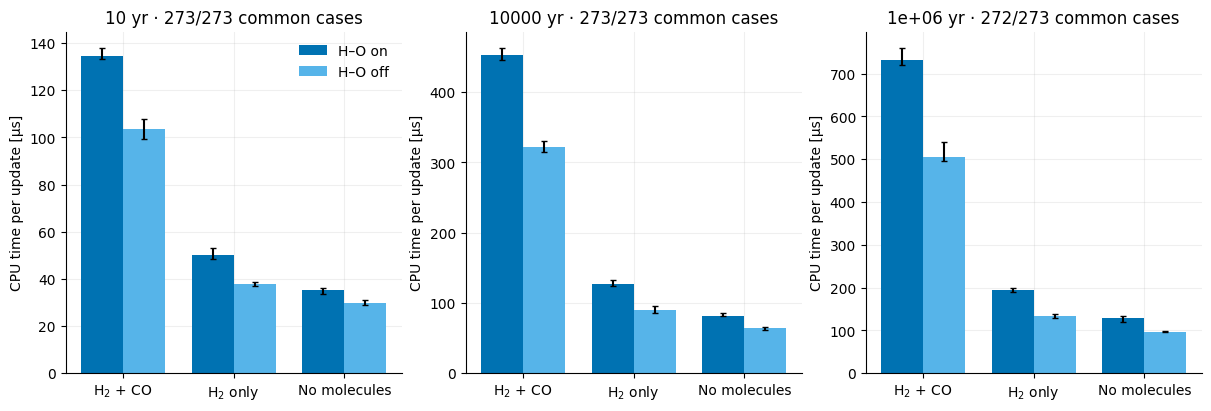

| 設定 | 10 年 [µs] | 10000 年 [µs] | 1e+06 年 [µs] |
|---|---:|---:|---:|
| `h2_co_ct` | 134.3 | 453.3 | 731.2 |
| `h2_co` | 103.6 | 322.4 | 506.3 |
| `h2_ct` | 50.2 | 126.3 | 195.1 |
| `h2` | 38.0 | 90.3 | 134.0 |
| `atomic_ct` | 35.3 | 82.1 | 128.0 |
| `atomic` | 29.8 | 64.2 | 97.5 |

In [2]:
with plt.rc_context(PLOT_STYLE):
    fig = plot_timings(steps, timing)
    display(fig)
    plt.close(fig)

table = ["| 設定 | " + " | ".join(f"{dt:g} 年 [µs]" for dt in steps) + " |",
         "|---|" + "---:|" * len(steps)]
for mode in MODES:
    times = [f"{timing[dt, mode][0]:.1f}" for dt in steps]
    table.append(f"| `{mode}` | " + " | ".join(times) + " |")
display(Markdown("\n".join(table)))

## エネルギー更新後の差

比較する両設定で収束した条件を対応づけます。温度は基準設定に対する相対差、存在比と $\Delta U/U_0$ は絶対差をパーセントポイントで表示します。

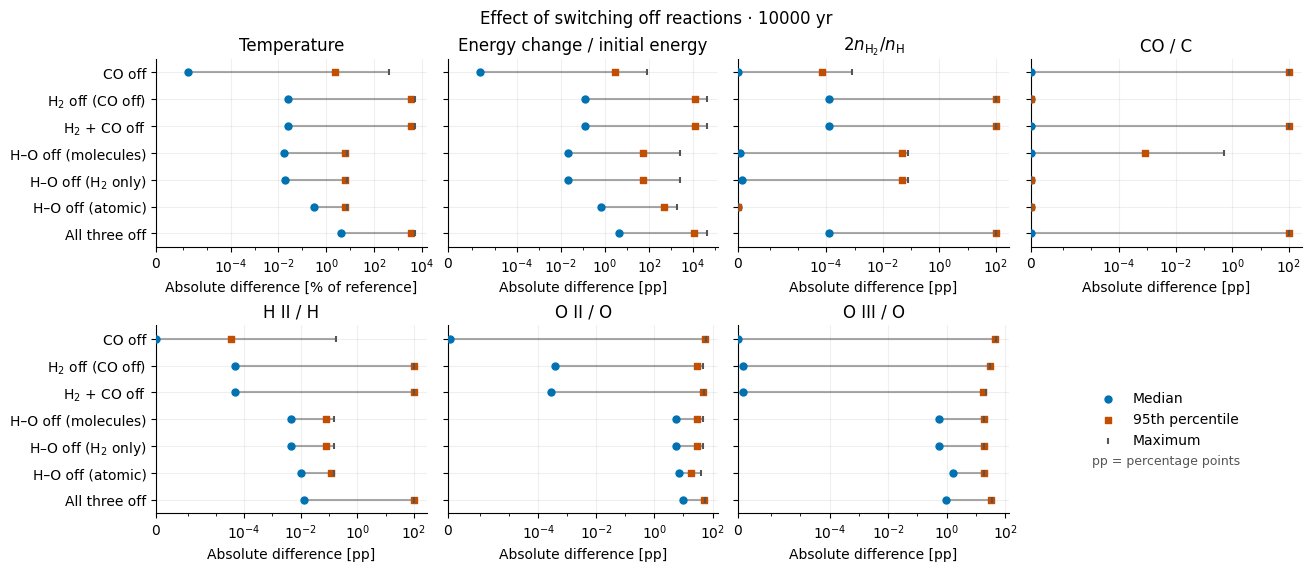

In [3]:
with plt.rc_context(PLOT_STYLE):
    fig = plot_effects(summary, dt_years)
    display(fig)
    plt.close(fig)

## 温度差とガスの条件

各点は初期の密度・温度・電離光子束を表します。色は更新後の温度の符号付き相対差です。

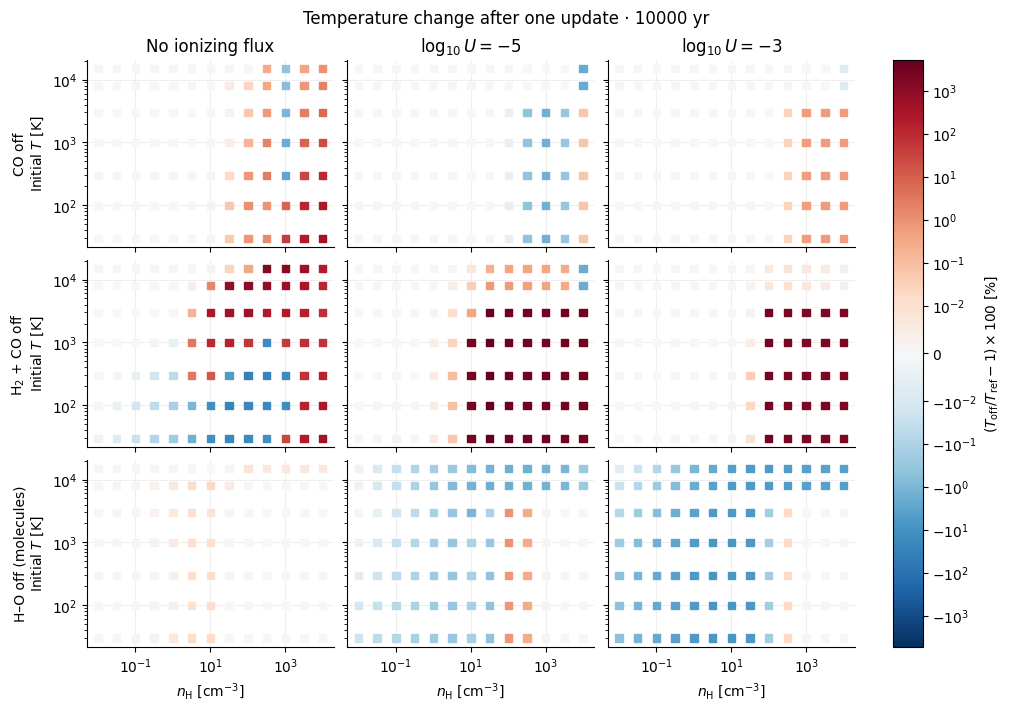

In [4]:
with plt.rc_context(PLOT_STYLE):
    fig = plot_temperature(data, dt_years)
    display(fig)
    plt.close(fig)